# HOMEWORK 9

Done by: **Bohdan Pinchuk**

Link: https://github.com/BogdanPinchuk/ComputerVision-PBY_HW9

In this homework, you are going to use the dlib face detector and apply it to an image of your liking. You can follow the procedure shown in lesson 9. Please always comment your code so I can see what you're doing :-)

For this homework we are not going to provide you with any code, you'll have to build the face detector on your own.

In [1]:
# Silent installation or update

# Clean cache
!python3 -m pip cache purge -q

# Force updating
package_update = [
    "pip",
    "scikit-learn",
    "pandas",
]

for package_name in package_update:
    !bash -c "python3 -m pip install -U '{package_name}' -q"

# Install missing packages
package_array = [
    "jinja2",
    "ipywidgets",
    "nbformat",
    "numpy",
    "matplotlib",
    "opencv-python",
    "cmake",
    "dlib-bin",
]

for package_name in package_array:
    !bash -c "python3 -m pip show '{package_name}' > /dev/null 2>&1 || python3 -m pip install -U '{package_name}' -q"


In [2]:
# Synchronization with remote source

import shutil
from pathlib import Path

# Input images
hm_version = 9

# Solution
git_project_url = f"https://github.com/BogdanPinchuk/ComputerVision-PBY_HW{hm_version}.git"
main_file_name = f"Bohdan_Pinchuk_CV_HW{hm_version}.ipynb"

# upload all files
current_path = !pwd
current_path = current_path[0]
parent_path = !dirname "$current_path"
parent_path = parent_path[0]
temp_path = f"{parent_path}/temp"

# Clone images
!rm -rf "$temp_path"
!git clone "$git_project_url" "$temp_path"

source = Path(temp_path)
destination = Path(current_path)
exclude = {main_file_name, ".git", ".idea"}

for item in source.iterdir():
    if item.name in exclude:
        continue

    target = destination / item.name
    if item.is_dir():
        shutil.copytree(item, target, dirs_exist_ok=True)
    else:
        shutil.copy2(item, target)

# Clean temp folder
!rm -rf "$temp_path"

# Note. To upload big files to GitHub, execute the next command in the terminal
# 1. brew install git-lfs
# 2. git lfs install
# 3.1. git lfs track "*.safetensors"
# 3.2. git lfs track "*.bin"

### Step 0

Run the necessary imports.

### Step 1

Load an image (any image that contains faces).

### Step 2

Load the dlib face detector.

### Step 3

Run the detector on your image.

### Step 4

Draw bounding boxes around the detected faces and plot the image. Use different colour for each face.

### Step 5 (optional)

Repeat the process with a different and more challenging image (more faces, smaller faces, people with glasses, hats, helmets, etc.). How does the detector perform? Is it robust?

In [3]:
# Load data

import apps.main as mn

# Input data
n_images = 10

# Solution
images_dict_1 = {}

for idx in range(n_images):
    # form file name
    file_name = f"ir_{idx}.png"
    file_path = f"resources/images/{file_name}"
    # load image
    img_rgb = mn.load_image(file_path)
    # add image to dictionary
    images_dict_1[file_name] = img_rgb

# Print results


In [4]:
# Face detection

import cv2
import dlib
import copy
import itertools
import numpy as np
import matplotlib.pyplot as plt

# Input data
thickness = 15
color_palette_name = 'tab20'
images_dict_2 = copy.deepcopy(images_dict_1)

# Solution
# get colors map
cmap = (np.asarray(plt.get_cmap(color_palette_name).colors) * 255).astype(int).tolist()  # type: ignore
# extract colors and convert
colors = itertools.cycle(tuple(color) for color in cmap)

detector = dlib.get_frontal_face_detector()

for item in images_dict_2.items():
    name = item[0]
    image = item[1]
    # detection faces
    detected_faces = detector(image, 1)

    # draw rectangle over the face
    for face in detected_faces:
        # extract coordinates
        x1, y1, x2, y2 = face.left(), face.top(), face.right(), face.bottom()
        # get color
        current_color = next(colors)
        # draw rectangle
        cv2.rectangle(image, (x1, y1), (x2, y2), current_color, thickness)
        # save image
        images_dict_2[name] = image


# Print results


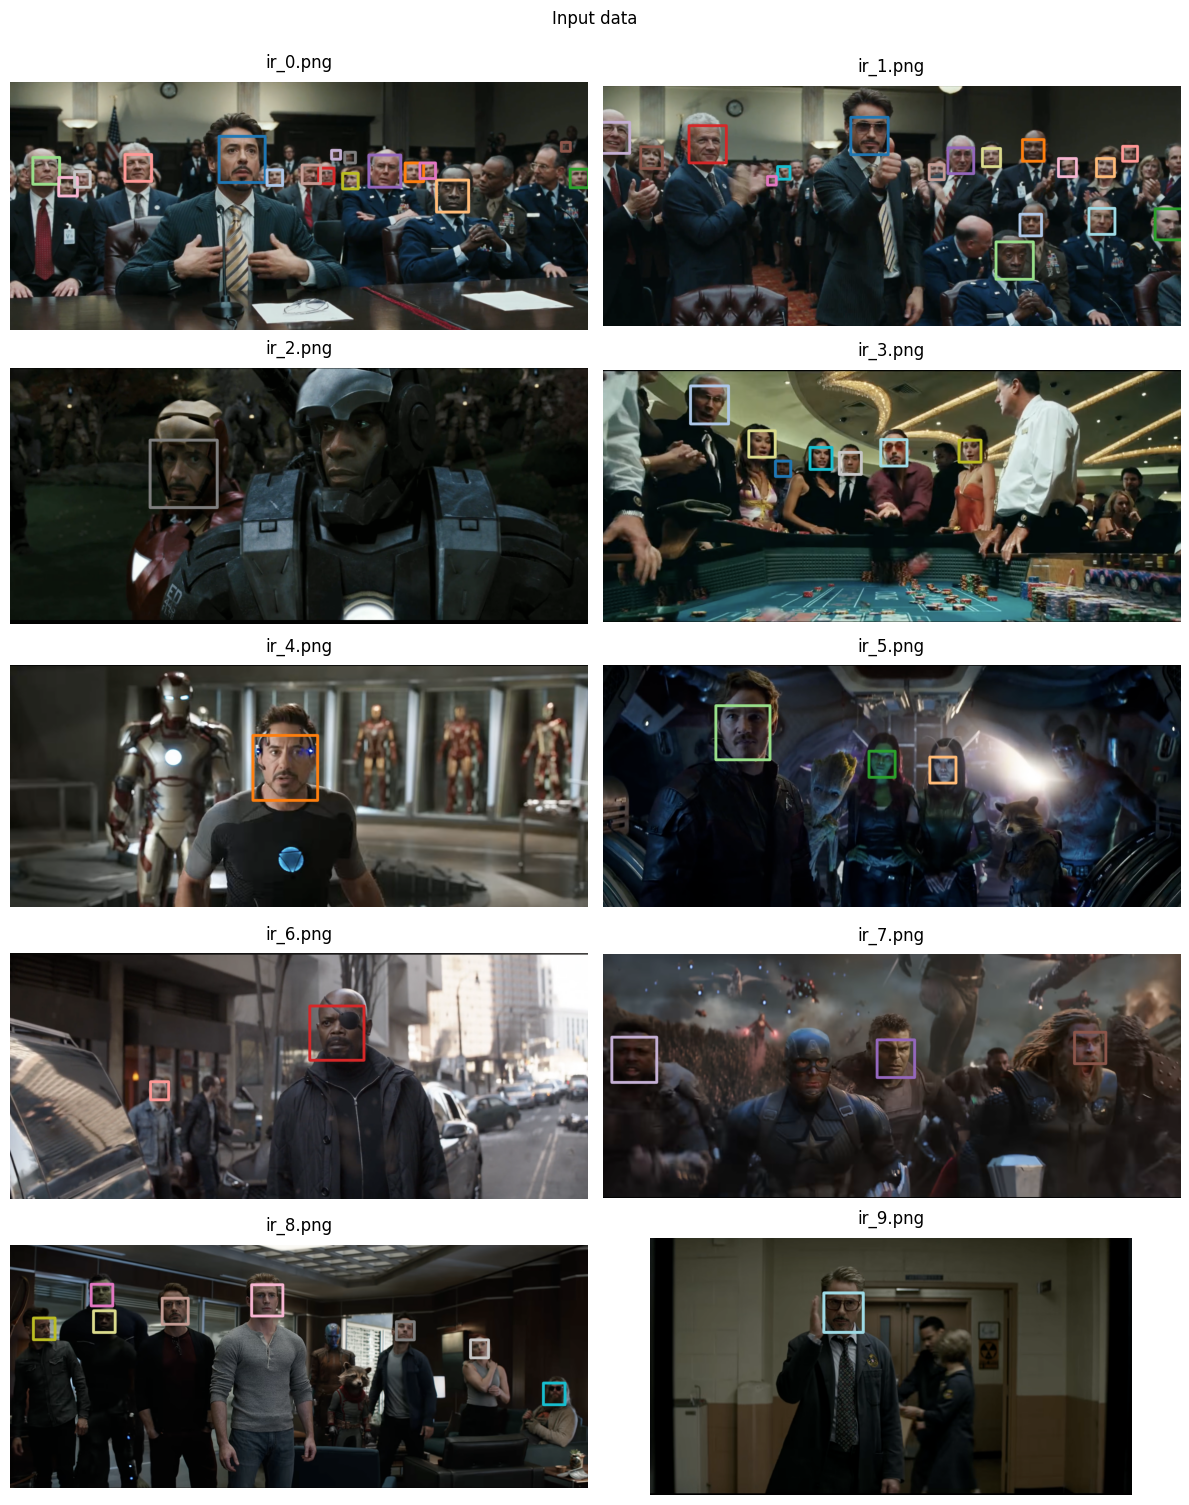

In [5]:
# Graphic results

import math
import numpy as np
import matplotlib.pyplot as plt

# Input data
n_img_cols = 2
images_dict = images_dict_2
n_img_rows = math.ceil(len(images_dict) / n_img_cols)

# Solution
_, axes = plt.subplots(n_img_rows, n_img_cols, figsize=(12, 3 * n_img_rows))
axes_list = np.array(axes).flatten()

for idx, (img_name, img_data) in enumerate(images_dict.items()):
    ax = axes_list[idx]
    ax.set_title(img_name, pad=10, loc='center', color='black')
    if len(img_data.shape) == 3:
        ax.imshow(img_data)
    else:
        ax.imshow(img_data, cmap='gray')
    ax.axis(False)

# remove empty charts
for idx in range(len(images_dict), len(axes_list)):
    axes_list[idx].remove()

# Plot
plt.suptitle("Input data", y=1.0)
plt.tight_layout()
plt.show()


### Conclusion
1. Angle and Orientation Efficiency: The algorithm demonstrated high accuracy in detecting frontal faces. However, the standard frontal detector failed to recognize faces rotated at an angle of 35-45 degrees (closer to a profile view) due to the significant distortion of key facial geometry and outlines.
2. Impact of Scale and Quality: While the detector handles faces at varying distances well, it misses highly distant faces in the background. This limitation is primarily caused by low resolution and blurring.
3. Handling of Accessories and Partial Occlusions: The model shows excellent robustness against localized facial obstructions. Faces are successfully detected even with glasses, open combat helmets, attached external devices, and even with a pirate-style eye patch. However, when a face is covered by a full mask that hides crucial features, the detection fails entirely.
4. Specificity with Non-Human Faces and Skin Tones: The detector is trained strictly on the textures and anatomical proportions of human faces. Altering the skin to an unnatural color (common for sci-fi characters) or attempting to detect animal faces (e.g., Rocket Raccoon) results in failure.